# Capture activation traces

Run from this notebook's directory. One dense forward per prompt records projection-input importance and saves `activation_traces.npz`. Continue with [02_02_global_oracle.ipynb](02_02_global_oracle.ipynb) to save the reference, then [02_03_selector_sweep.ipynb](02_03_selector_sweep.ipynb) to evaluate selectors and [02_04_analyze_oracle.ipynb](02_04_analyze_oracle.ipynb) for the figures.

PyTorch and Transformers load the checkpoint below; an uncached checkpoint is downloaded.

In [22]:
from pathlib      import Path
from transformers import AutoModelForCausalLM, AutoTokenizer

import json
import torch
import numpy as np

In [23]:
TRACE          = Path("activation_traces.npz")
MODEL_ID       = "Qwen/Qwen2.5-0.5B-Instruct"
MODEL_REVISION = "7ae557604adf67be50417f59c2c2f167def9a775"

PROMPTS = (
    "Explain why contiguous flash reads can be faster than scattered reads.",
    "Summarize the trade-off between neural-network sparsity and accuracy.",
    "Write a short Python function that computes a moving average.",
)

## 1. Load the model

In [24]:
# bring cuda as device
device = "cuda" if torch.cuda.is_available() else "cpu"

# bring tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)

# bring model onto device
net = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, 
    revision=MODEL_REVISION, 
    torch_dtype=torch.bfloat16
).to(device).eval()

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 532.22it/s, Materializing param=model.norm.weight]                              


## 2. Record projection inputs

A pre-forward hook records $v_i=\operatorname{mean}_{\rm batch,token}|x_i|$ at each attention or MLP projection. Absolute values and means are computed in the activation dtype, then converted to float32. The dense forward uses the original activations.

In [25]:
def record(name):
    def hook(layer, inputs):

        # number of input/output channels
        n, d = layer.in_features, layer.out_features

        # calculate trance_id inside entries
        trace_id = len(entries)
        key = f"values_{trace_id:06d}"

        # Mean absolute activation (i.e importance) 
        # for each input channel
        values = inputs[0].detach()
        values = values.abs()
        values = values.reshape(-1, n)
        values = values.mean(0)
        arrays[key] = values.float().cpu().numpy()

        # Metadata describing the saved array.
        entries.append({
            "trace_id":    trace_id,
            "input_index": input_index,
            "module":      name,
            "n":           n,
            "d":           d,
            "shape":       f"{n}x{d}",
            "array":       key,
            "num_tokens":  int(tokens["input_ids"].numel()),
        })

    return hook

In [26]:
# results to be saved in .npz file
entries, arrays = [], {}

In [27]:
# needed to remove hooks after the job
hooks = []

try:
    # register hooks on projection layers.
    for name, layer in net.named_modules():
        if (
            isinstance(layer, torch.nn.Linear)
            and ".layers." in name
            and name.endswith("_proj")
        ):
            hooks.append(layer.register_forward_pre_hook(record(name)))

    # run one forward pass per prompt.
    with torch.inference_mode():
        for input_index, prompt in enumerate(PROMPTS):
            
            # format the user message and append the assistant response prefix.
            text = tokenizer.apply_chat_template(
                [{"role": "user", "content": prompt}],
                tokenize=False,
                add_generation_prompt=True,
            )

            # tokenize with a 256-token limit and move tensors to the device.
            tokens = tokenizer(
                text,
                return_tensors="pt",
                truncation=True,
                max_length=256,
            ).to(device)

            # run a forward pass to capture layer inputs through the hooks.
            net(**tokens, use_cache=False)

            # print progress rate
            print(f"Prompt {input_index + 1} captured")

finally:
    # remove hooks even if capture fails.
    for handle in hooks:
        handle.remove()

Prompt 1 captured
Prompt 2 captured
Prompt 3 captured


## 3. Save the archive

Store the vectors with projection dimensions, prompt indices, model revision and dtype.

In [28]:
model_dtype = str(next(net.parameters()).dtype).split(".")[-1]

# model and trace metadata.
manifest = {
    "model":          MODEL_ID,
    "model_revision": MODEL_REVISION,
    "model_dtype":    model_dtype,
    "prompts":        list(PROMPTS),
    "prompt_count":   len(PROMPTS),
    "traces":         entries,
    "trace_count":    len(entries),
}

# save metadata and activation arrays.
manifest_json = np.asarray(json.dumps(manifest))
np.savez_compressed(
    TRACE,
    manifest_json=manifest_json,
    **arrays,
)

manifest["trace_count"]

504

## 4. Inspect the traces

In [29]:
# preview the first entry and first 10 values of each array.

entry = entries[0]

print("Entry:")
print(json.dumps(entry, indent=2))

key = entry["array"]
values = arrays[key]

print(f"Array {key}, shape={values.shape}:")
print(values[:10])
print()


Entry:
{
  "trace_id": 0,
  "input_index": 0,
  "module": "model.layers.0.self_attn.q_proj",
  "n": 896,
  "d": 896,
  "shape": "896x896",
  "array": "values_000000",
  "num_tokens": 42
}
Array values_000000, shape=(896,):
[0.0279541  0.04125977 0.01989746 0.06201172 0.04370117 0.03076172
 0.03588867 0.02575684 0.07714844 0.0222168 ]



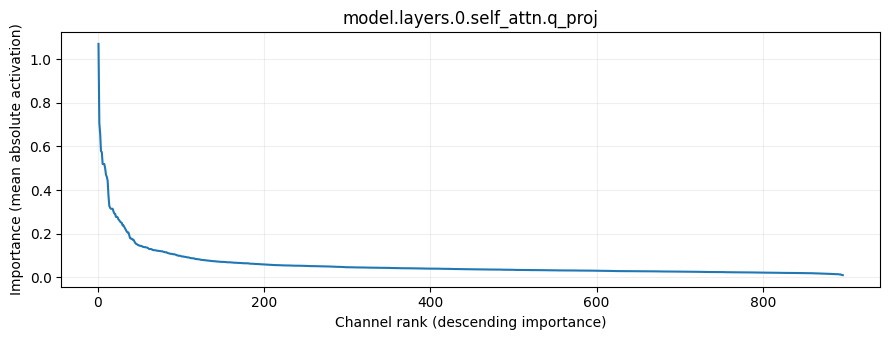

In [30]:
import matplotlib.pyplot as plt

# sort a copy by importance, from largest to smallest.
sorted_values = np.sort(values)[::-1]
ranks = np.arange(1, len(sorted_values) + 1)

plt.figure(figsize=(9, 3.5))
plt.plot(ranks, sorted_values)
plt.title(entry["module"])
plt.xlabel("Channel rank (descending importance)")
plt.ylabel("Importance (mean absolute activation)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
